In [25]:
# already downloaded
# import kagglehub

# data = kagglehub.dataset_download("mlg-ulb/creditcardfraud",output_dir=f"../data/raw", force_download=True)
# print("Path to dataset files:", data)

In [26]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv(f'../data/raw/creditcard.csv')
df.columns = (cols.replace(" ", "_").lower() for cols in df.columns)

In [27]:
df.columns

Index(['time', 'v1', 'v2', 'v3', 'v4', 'v5', 'v6', 'v7', 'v8', 'v9', 'v10',
       'v11', 'v12', 'v13', 'v14', 'v15', 'v16', 'v17', 'v18', 'v19', 'v20',
       'v21', 'v22', 'v23', 'v24', 'v25', 'v26', 'v27', 'v28', 'amount',
       'class'],
      dtype='str')

In [28]:
df.describe()

,time,v1,v2,v3,v4,v5,v6,v7,v8,v9,...,v21,v22,v23,v24,v25,v26,v27,v28,amount,class
count,284807.000000,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,...,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,2.848070e+05,284807.000000,284807.000000
mean,94813.859575,1.175161e-15,3.384974e-16,-1.379537e-15,2.094852e-15,1.021879e-15,1.494498e-15,-5.620335e-16,1.149614e-16,-2.414189e-15,...,1.628620e-16,-3.576577e-16,2.618565e-16,4.473914e-15,5.109395e-16,1.686100e-15,-3.661401e-16,-1.227452e-16,88.349619,0.001727
std,47488.145955,1.958696e+00,1.651309e+00,1.516255e+00,1.415869e+00,1.380247e+00,1.332271e+00,1.237094e+00,1.194353e+00,1.098632e+00,...,7.345240e-01,7.257016e-01,6.244603e-01,6.056471e-01,5.212781e-01,4.822270e-01,4.036325e-01,3.300833e-01,250.120109,0.041527
min,0.000000,-5.640751e+01,-7.271573e+01,-4.832559e+01,-5.683171e+00,-1.137433e+02,-2.616051e+01,-4.355724e+01,-7.321672e+01,-1.343407e+01,...,-3.483038e+01,-1.093314e+01,-4.480774e+01,-2.836627e+00,-1.029540e+01,-2.604551e+00,-2.256568e+01,-1.543008e+01,0.000000,0.000000
25%,54201.500000,-9.203734e-01,-5.985499e-01,-8.903648e-01,-8.486401e-01,-6.915971e-01,-7.682956e-01,-5.540759e-01,-2.086297e-01,-6.430976e-01,...,-2.283949e-01,-5.423504e-01,-1.618463e-01,-3.545861e-01,-3.171451e-01,-3.269839e-01,-7.083953e-02,-5.295979e-02,5.600000,0.000000
50%,84692.000000,1.810880e-02,6.548556e-02,1.798463e-01,-1.984653e-02,-5.433583e-02,-2.741871e-01,4.010308e-02,2.235804e-02,-5.142873e-02,...,-2.945017e-02,6.781943e-03,-1.119293e-02,4.097606e-02,1.659350e-02,-5.213911e-02,1.342146e-03,1.124383e-02,22.000000,0.000000
75%,139320.500000,1.315642e+00,8.037239e-01,1.027196e+00,7.433413e-01,6.119264e-01,3.985649e-01,5.704361e-01,3.273459e-01,5.971390e-01,...,1.863772e-01,5.285536e-01,1.476421e-01,4.395266e-01,3.507156e-01,2.409522e-01,9.104512e-02,7.827995e-02,77.165000,0.000000
max,172792.000000,2.454930e+00,2.205773e+01,9.382558e+00,1.687534e+01,3.480167e+01,7.330163e+01,1.205895e+02,2.000721e+01,1.559499e+01,...,2.720284e+01,1.050309e+01,2.252841e+01,4.584549e+00,7.519589e+00,3.517346e+00,3.161220e+01,3.384781e+01,25691.160000,1.000000


In [29]:
df.head()

,time,v1,v2,v3,v4,v5,v6,v7,v8,v9,...,v21,v22,v23,v24,v25,v26,v27,v28,amount,class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [30]:
df.isnull().sum()

time      0
v1        0
v2        0
v3        0
v4        0
v5        0
v6        0
v7        0
v8        0
v9        0
v10       0
v11       0
v12       0
v13       0
v14       0
v15       0
v16       0
v17       0
v18       0
v19       0
v20       0
v21       0
v22       0
v23       0
v24       0
v25       0
v26       0
v27       0
v28       0
amount    0
class     0
dtype: int64

In [31]:
df.duplicated().sum()

np.int64(1081)

In [32]:
df[df.duplicated()]

,time,v1,v2,v3,v4,v5,v6,v7,v8,v9,...,v21,v22,v23,v24,v25,v26,v27,v28,amount,class
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
113,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
114,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
115,74.0,1.038370,0.127486,0.184456,1.109950,0.441699,0.945283,-0.036715,0.350995,0.118950,...,0.102520,0.605089,0.023092,-0.626463,0.479120,-0.166937,0.081247,0.001192,1.18,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
282987,171288.0,1.912550,-0.455240,-1.750654,0.454324,2.089130,4.160019,-0.881302,1.081750,1.022928,...,-0.524067,-1.337510,0.473943,0.616683,-0.283548,-1.084843,0.073133,-0.036020,11.99,0
283483,171627.0,-1.464380,1.368119,0.815992,-0.601282,-0.689115,-0.487154,-0.303778,0.884953,0.054065,...,0.287217,0.947825,-0.218773,0.082926,0.044127,0.639270,0.213565,0.119251,6.82,0
283485,171627.0,-1.457978,1.378203,0.811515,-0.603760,-0.711883,-0.471672,-0.282535,0.880654,0.052808,...,0.284205,0.949659,-0.216949,0.083250,0.044944,0.639933,0.219432,0.116772,11.93,0
284191,172233.0,-2.667936,3.160505,-3.355984,1.007845,-0.377397,-0.109730,-0.667233,2.309700,-1.639306,...,0.391483,0.266536,-0.079853,-0.096395,0.086719,-0.451128,-1.183743,-0.222200,55.66,0


In [33]:
df[df['time']==26]

,time,v1,v2,v3,v4,v5,v6,v7,v8,v9,...,v21,v22,v23,v24,v25,v26,v27,v28,amount,class
32,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
33,26.0,-0.529912,0.873892,1.347247,0.145457,0.414209,0.100223,0.711206,0.176066,-0.286717,...,0.046949,0.208105,-0.185548,0.001031,0.098816,-0.552904,-0.073288,0.023307,6.14,0
34,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0
35,26.0,-0.535388,0.865268,1.351076,0.147575,0.433680,0.086983,0.693039,0.179742,-0.285642,...,0.049526,0.206537,-0.187108,0.000753,0.098117,-0.553471,-0.078306,0.025427,1.77,0


In [34]:
df_ = df.drop_duplicates()
df_

,time,v1,v2,v3,v4,v5,v6,v7,v8,v9,...,v21,v22,v23,v24,v25,v26,v27,v28,amount,class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   time    284807 non-null  float64
 1   v1      284807 non-null  float64
 2   v2      284807 non-null  float64
 3   v3      284807 non-null  float64
 4   v4      284807 non-null  float64
 5   v5      284807 non-null  float64
 6   v6      284807 non-null  float64
 7   v7      284807 non-null  float64
 8   v8      284807 non-null  float64
 9   v9      284807 non-null  float64
 10  v10     284807 non-null  float64
 11  v11     284807 non-null  float64
 12  v12     284807 non-null  float64
 13  v13     284807 non-null  float64
 14  v14     284807 non-null  float64
 15  v15     284807 non-null  float64
 16  v16     284807 non-null  float64
 17  v17     284807 non-null  float64
 18  v18     284807 non-null  float64
 19  v19     284807 non-null  float64
 20  v20     284807 non-null  float64
 21  v21     284807 non-nu

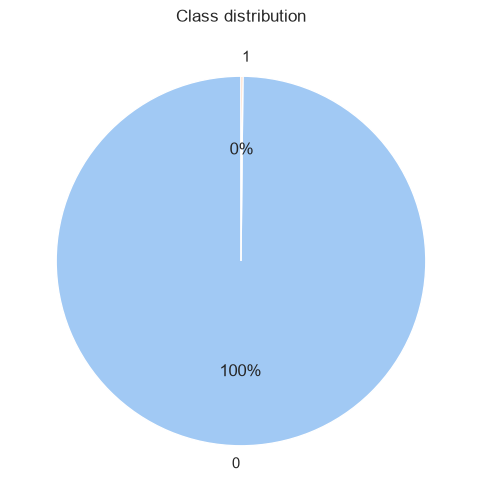

In [36]:
colors = sns.color_palette('pastel')[0:len(df)]

plt.figure(figsize=(6, 6))
class_ = df_['class'].value_counts()

plt.pie(
    class_.values,
    labels=class_.index,
    colors=colors[:len(class_)],
    autopct='%.0f%%',
    startangle=90
)
plt.title("Class distribution")
plt.show()

it shows that we are working with extremely unequal class distribution. which makes sense since this is for credit card fraud detection (99% of the time, the transaction is valid).

In [37]:
print(df_['class'].value_counts())

class
0    283253
1       473
Name: count, dtype: int64


there seems to be only 473 of class 1 i.e. they are indeed fraud. for this we can use stratify=y in train_test_split as well as models for managing unequal class distribution.

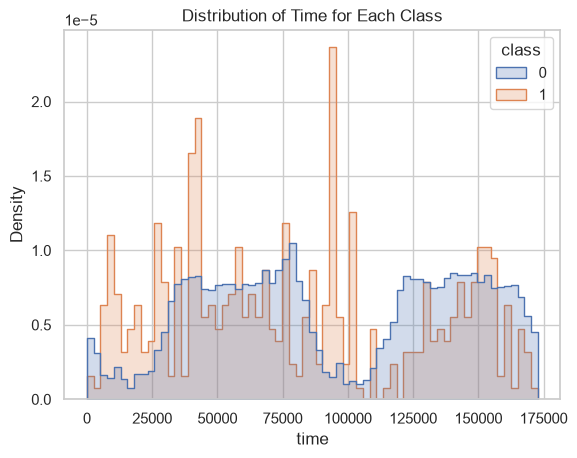

In [38]:
sns.histplot(data=df, x='time', hue='class', element='step', stat='density', common_norm=False)
plt.title('Distribution of Time for Each Class')
plt.show()

from the plot above, time seems like time elapsed from tranaction (roughly 2 days). the legitimate transactions are smooth-ish curve. whereas, the fraud cases has spikes and not smooth at all.

both of them seem to be dropping between 75,000 and 125,000 seconds which makes sense, since it is midnight (roughly 1 to 6 am).

but at the same time, the plot makes it clear if transaction are happening in the middle of the night, it is most likely a fraud one.

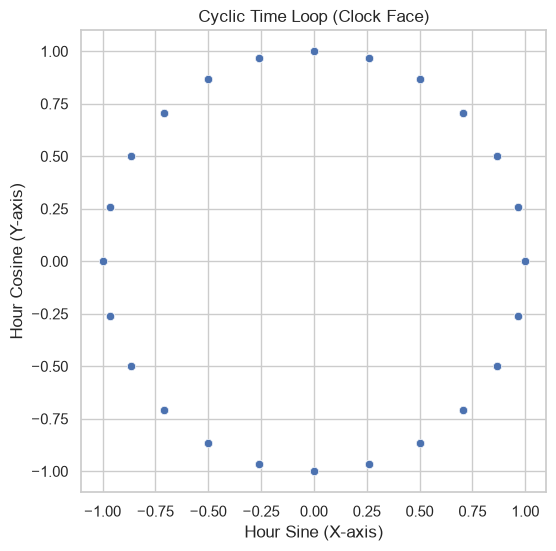

In [39]:
# converting the time into hours in a day
df_['hour'] = (df_['time'] // 3600) % 24

# for mapping the hours into 24 hours day (0 to 23)
df_['hour_sin'] = np.sin(2 * np.pi * df_['hour'] / 24.0)
df_['hour_cos'] = np.cos(2 * np.pi * df_['hour'] / 24.0)

plt.figure(figsize=(6,6))
sns.scatterplot(data=df_.sample(1000), x='hour_sin', y='hour_cos')
plt.title("Cyclic Time Loop (Clock Face)")
plt.xlabel("Hour Sine (X-axis)")
plt.ylabel("Hour Cosine (Y-axis)")
plt.show()

why mapping feature time into 24 hours time? while researching i found out that model performs better in dataset with cycle like this. because if we only send df_['hours'], the model may simply understand it as 0 being the least and 23 being the highest, but if we make hour_sin and hour_cos they will act as cordinate thus provide model with mathematical clarity of circle of time.

more on that later (while model prototyping).

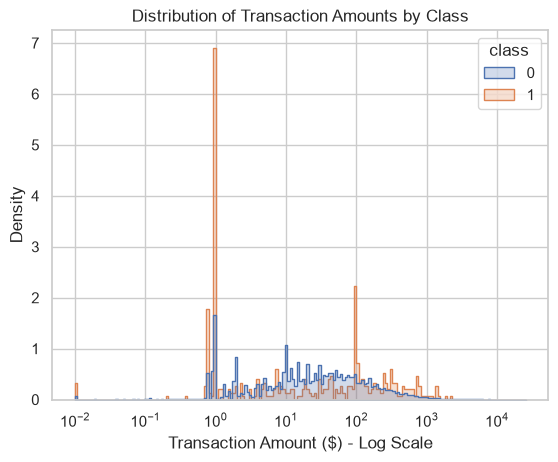

In [40]:
sns.histplot(data=df_, x='amount', hue='class', element='step', stat='density', common_norm=False, log_scale=True)

plt.title('Distribution of Transaction Amounts by Class')
plt.xlabel('Transaction Amount ($) - Log Scale')
plt.show()

we again see the same kind of smoothness and scatterness of amount from legitimate and fraud cases respectively.

legitimate transactions are pretty smooth. whereas the fraud cases are spiky and has lack of smoothness.

at 10^0 or 1, there seem to be huge spike of both legitimate and fraud transactions. Of course, fraud transactions are way more than the legitimate ones. which slightly makes sense. fraudsters mainly check if credit card is working or not by taking out or transacting 1 $.

at 10^2 or 100 there seems to be another spike in transaction, which seems to imply that fraudsters target clean number like 100.

and fraud cases are seem to be hovering more around 10^3 or 1000, which seems to indicate that fraudsters take out higher amount transactions, after checking if the card works or not.

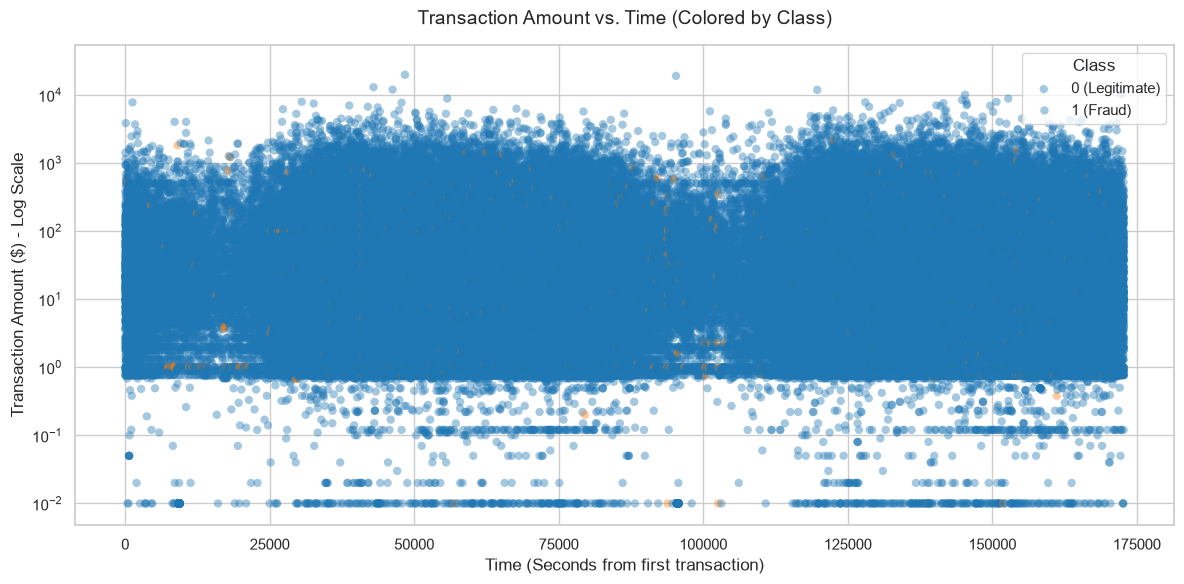

In [41]:
sns.set_theme(style='whitegrid')
plt.figure(figsize=(12, 6))
sns.scatterplot(
    data=df_, 
    x='time', 
    y='amount', 
    hue='class', 
    palette={0: '#1f77b4', 1: '#ff7f0e'}, 
    alpha=0.4, 
    linewidth=0,
    rasterized=True
)

plt.yscale('log')
plt.title('Transaction Amount vs. Time (Colored by Class)', fontsize=14, pad=15)
plt.xlabel('Time (Seconds from first transaction)', fontsize=12)
plt.ylabel('Transaction Amount ($) - Log Scale', fontsize=12)
plt.legend(title='Class', labels=['0 (Legitimate)', '1 (Fraud)'], loc='upper right')
plt.tight_layout()
plt.show()

above plots shows the relationship between time elapsed and transaction amount.

this plots shows complete 2 valleys (24 hour time). peak at 50,000 and 150,000 which makes sense since they are middle of the day.

plot also makes it clear that fraud or legitimate transaction happens nearly every hour. but at the same time, there seem to be slight concerntration of fraudulant transaction around middle of the night (around 2 3 am). which could make sense, banks are not opened at that time, so it would take people time to realise and thus report the frauds.

and micro transactions seem to be happening alot (around 10^-2 or 0.01), which could be fraudsters testing if the card works or not.

as there are vast number of features v1 to v28 (they are output of pca - as per the dataset creator), there are too many of them to use every single one of them to figure out their corr to class. so, look below for robust comparision 

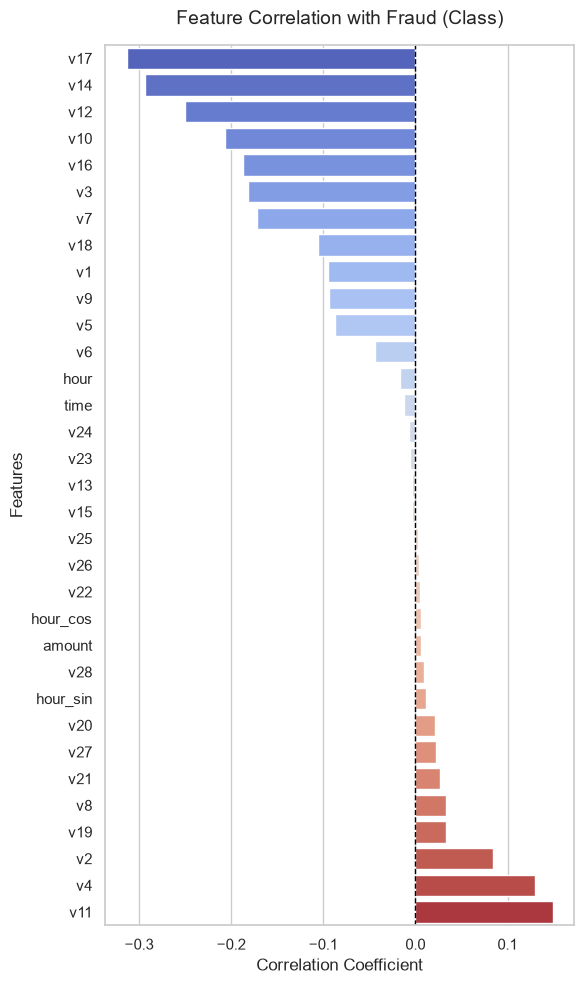

In [42]:
corr = df_.corr()
class_corr = corr['class'].drop('class').sort_values()

plt.figure(figsize=(6, 10))
sns.barplot(
    x=class_corr.values, 
    y=class_corr.index, 
    hue=class_corr.index, 
    palette='coolwarm', 
    legend=False
)
plt.title('Feature Correlation with Fraud (Class)', fontsize=14, pad=15)
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.tight_layout()
plt.show()

v17, v14, and v12 seem to be correlated negatively to the class 1, where as v11, v4 and to some extent v2 seem to be correlated positively to class 1.

while other features seem to be deadweight.

not dropping the features yet as they will be dropped once we have prototype model, then use shap explainer.

In [43]:
df_.columns

Index(['time', 'v1', 'v2', 'v3', 'v4', 'v5', 'v6', 'v7', 'v8', 'v9', 'v10',
       'v11', 'v12', 'v13', 'v14', 'v15', 'v16', 'v17', 'v18', 'v19', 'v20',
       'v21', 'v22', 'v23', 'v24', 'v25', 'v26', 'v27', 'v28', 'amount',
       'class', 'hour', 'hour_sin', 'hour_cos'],
      dtype='str')

In [44]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler, StandardScaler

X = df_.drop(columns=['class'])
y = df_['class']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_train = X_train.copy()
X_test = X_test.copy()

for dataset in [X_train, X_test]: 
    dataset['hour'] = (dataset['time'] // 3600) % 24
    dataset['hour_sin'] = np.sin(2 * np.pi * dataset['hour'] / 24.0)
    dataset['hour_cos'] = np.cos(2 * np.pi * dataset['hour'] / 24.0)
    dataset.drop(columns=['time', 'hour'], inplace=True)

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

amount_scaler = RobustScaler()
X_train_scaled['amount'] = amount_scaler.fit_transform(X_train_scaled[['amount']])
X_test_scaled['amount'] = amount_scaler.transform(X_test_scaled[['amount']])

pca_cols = [col for col in X_train.columns if col.startswith('v')]

feature_scaler = StandardScaler()
X_train_scaled[pca_cols] = feature_scaler.fit_transform(X_train_scaled[pca_cols])
X_test_scaled[pca_cols] = feature_scaler.transform(X_test_scaled[pca_cols])

In [45]:
print(X_train_scaled.describe())

                 v1            v2            v3            v4            v5  \
count  2.269800e+05  2.269800e+05  2.269800e+05  2.269800e+05  2.269800e+05   
mean   6.699099e-18 -1.202081e-17  8.514742e-18 -2.654596e-17  1.339820e-17   
std    1.000002e+00  1.000002e+00  1.000002e+00  1.000002e+00  1.000002e+00   
min   -2.896978e+01 -4.407711e+01 -2.234715e+01 -4.009399e+00 -2.360704e+01   
25%   -4.729207e-01 -3.610299e-01 -5.900694e-01 -5.979342e-01 -5.104934e-01   
50%    6.845720e-03  4.205161e-02  1.168841e-01 -1.409621e-02 -4.223030e-02   
75%    6.729237e-01  4.891300e-01  6.802567e-01  5.246624e-01  4.489577e-01   
max    1.258110e+00  1.337482e+01  6.223468e+00  1.191100e+01  2.559261e+01   

                 v6            v7            v8            v9           v10  \
count  2.269800e+05  2.269800e+05  2.269800e+05  2.269800e+05  2.269800e+05   
mean  -1.101908e-17 -8.452134e-18  7.513008e-19  8.013875e-18  6.761707e-18   
std    1.000002e+00  1.000002e+00  1.000002e+00  1.

let's first use this dataset and check how the model performs, and if it doesn't perform as well as we would like it to be, we could generate and use synthetic fraud set.

let's prototype LogisticRegression, RandomForestClassifier, XGBClassifier, LGBMClassifier, and neural network.

In [46]:
# necessary imports
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, f1_score, precision_score, recall_score, roc_auc_score
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import tensorflow as tf
from tensorflow.keras import Sequential
from keras.layers import Dense, Dropout
from keras.optimizers import Adam
from scikeras.wrappers import KerasClassifier

In [47]:
neg, pos = np.bincount(y_train)
total = neg + pos
weight_for_0 = (1 / neg) * (total / 2.0)
weight_for_1 = (1 / pos) * (total / 2.0)
nn_class_weights = {0: weight_for_0, 1: weight_for_1}

def create_nn_model(layers=1, neurons=32, dropout_rate=0.2):
    model = Sequential()
    model.add(Dense(neurons, activation='relu', input_shape=(X_train.shape[1],)))
    model.add(Dropout(dropout_rate))
    
    for _ in range(layers - 1):
        model.add(Dense(neurons, activation='relu'))
        model.add(Dropout(dropout_rate))
        
    model.add(Dense(1, activation='sigmoid'))
    
    model.compile(optimizer=Adam(), loss='binary_crossentropy') 
    return model

# when the model calculates its error,
# the error from misclassifying a minority instance (1) is multiplied by its class weight.
# it ensures that the optimizer (Adam) adjusts the internal neuron weights
# and biases aggressively enough to capture the pattern of fraud,
# rather than settling into a local minimum where it always predicts zero.
nn_wrapper = KerasClassifier(
    model=create_nn_model, 
    epochs=10, 
    verbose=0,
    fit__class_weight=nn_class_weights,
    model__layers=1,
    model__neurons=32,
    model__dropout_rate=0.2
)

model_dict = {
    # since we are working with highly imbalanced dataset, we are using the following
    
    # LR: to make sure the model is not overwhelmed by sheer volume of class 0
    'LogisticRegression': LogisticRegression(solver='saga', max_iter=1000, class_weight='balanced', random_state=42),
    # same reasoning as LR
    'RandomForest': RandomForestClassifier(class_weight='balanced', random_state=42),
    # XGBoost: evertime the xgbclassifier updates its tree, it gives more weight to fraud cases by roughly 500X
    'XGBoost': XGBClassifier(scale_pos_weight=weight_for_1/weight_for_0, random_state=42, eval_metric='logloss'),
    # LightGBM: to make sure the model gains information by correctly predicting fraud cases
    'LightGBM': LGBMClassifier(class_weight='balanced', random_state=42, verbose=1),
    'NeuralNetwork': nn_wrapper
}

# param_grids = {
#     'LogisticRegression': {
#         'C': np.logspace(-4, 4, 10),
#         'l1_ratio': [0.0, 0.2, 0.5, 0.8, 1.0]
#     },
#     'RandomForest': {
#         'n_estimators': [50, 100, 150, 200],
#         'max_depth': [5, 10, 20, None],
#         'min_samples_split': [2, 6, 10]
#     },
#     'XGBoost': {
#         'n_estimators': [50, 100, 150, 200],
#         'max_depth': [3, 5, 7],
#         'learning_rate': [0.01, 0.1, 0.2],
#         'subsample': [0.7, 0.9, 1.0]
#     },
#     'LightGBM': {
#         'n_estimators': [50, 100, 150, 200],
#         'max_depth': [3, 6, 10, -1],
#         'learning_rate': [0.01, 0.1, 0.2],
#         'num_leaves': [20, 35, 50]
#     },
#     'NeuralNetwork': {
#         'model__layers': [1, 2, 3],
#         'model__neurons': [16, 32, 64],
#         'model__dropout_rate': [0.1, 0.3],
#         'batch_size': [64, 128]
#     }
# }

param_grids = {
    'LogisticRegression': {
        'C': np.logspace(-2, 2, 5),
        'l1_ratio': [0.0, 0.5, 1.0]
    },
    'RandomForest': {
        'n_estimators': [50, 100, 150, 200],
        'max_depth': [10, 20, None],
        'min_samples_split': [2, 6, 10]
    },
    'XGBoost': {
        'n_estimators': [50, 100, 150, 200],
        'max_depth': [3, 5, 7],
        'learning_rate': [0.05, 0.1, 0.2],
        'subsample': [0.8, 1.0]
    },
    'LightGBM': {
        'n_estimators': [50, 100, 150, 200],
        'max_depth': [4, 8, -1],
        'learning_rate': [0.05, 0.1],
        'num_leaves': [15, 31, 63]
    },
    'NeuralNetwork': {
        'model__layers': [1, 2, 3],
        'model__neurons': [16, 32, 64],
        'model__dropout_rate': [0.2, 0.4],
        'batch_size': [128, 256]
    }
}

In [49]:
import os
import warnings

warnings.filterwarnings("ignore", category=UserWarning, module="keras")
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'

neg, pos = np.bincount(y_train)
total = neg + pos
weight_for_0 = (1 / neg) * (total / 2.0)
weight_for_1 = (1 / pos) * (total / 2.0)
nn_class_weights = {0: weight_for_0, 1: weight_for_1}

def create_nn_model(layers=1, neurons=32, dropout_rate=0.2):
    model = Sequential()
    model.add(Input(shape=(X_train.shape[1],)))
    model.add(Dense(neurons, activation='relu'))
    model.add(Dropout(dropout_rate))
    
    for _ in range(layers - 1):
        model.add(Dense(neurons, activation='relu'))
        model.add(Dropout(dropout_rate))
        
    model.add(Dense(1, activation='sigmoid'))
    model.compile(optimizer=Adam(), loss='binary_crossentropy') 
    return model

nn_wrapper = KerasClassifier(
    model=create_nn_model, 
    epochs=10, 
    verbose=0,
    fit__class_weight=nn_class_weights,
    model__layers=1,
    model__neurons=32,
    model__dropout_rate=0.2
)


In [50]:
results_list = []
best_models_dict = {}
models_requiring_scaling = ['NeuralNetwork', 'LogisticRegression', 'SVM', 'KNN']

for model_name, model in model_dict.items():
    print(f"Tuning and Training {model_name}...")
    X_tr, X_ts = (X_train_scaled, X_test_scaled) if model_name in models_requiring_scaling else (X_train, X_test)
    
    search = RandomizedSearchCV(
        estimator=model,
        param_distributions=param_grids[model_name],
        n_iter=5,
        cv=3,
        scoring='f1',
        random_state=42,
        n_jobs=1 if model_name == 'NeuralNetwork' else -1 
    )
    
    search.fit(X_tr, y_train)
    best_model = search.best_estimator_
    best_models_dict[model_name] = best_model
    
    y_pred = best_model.predict(X_ts)
    results_list.append({
        'Model': model_name,
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_pred)
    })

df_metrics = pd.DataFrame(results_list)
print("\nFinal Test Metrics Comparison Table:")
print(df_metrics.to_string(index=False))

Tuning and Training LogisticRegression...


c:\Users\PC-01\Desktop\Project\credit-card-fraud-ml\.venv\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Tuning and Training RandomForest...
Tuning and Training XGBoost...
Tuning and Training LightGBM...
[LightGBM] [Info] Number of positive: 378, number of negative: 226602
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.083511 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 7434
[LightGBM] [Info] Number of data points in the train set: 226980, number of used features: 31
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
[LightGBM] [Info] Start training from score 0.000000
Tuning and Training NeuralNetwork...

Final Test Metrics Comparison Table:
             Model  Precision   Recall  F1-Score  ROC-AUC
LogisticRegression   0.056772 0.873684  0.106615 0.924671
      RandomForest   0.945946 0.736842  0.828402 0.868386
           XGBoost   0.936709 0.778947  0.850575 0.889430
          LightGBM   0.701923 0.768421  0.733668 0.883937
     NeuralNetwork   0.096698 0.863158  0.17

<h3>which one to use in production</h3>

looking at the metrics XGBoost seem to offer good balance between precision and recall. it has precision of 93.6% and at the same time 77.89% recall. It seems to offer good precision-recall tradeoff balance.


looking at the metrics, Random forest and to certain extent LightGBM also offer similar model performance. especially random forest, its performance is highly comparable to that of XGBoost. But in this dataset, XGBoost seem to have slight edge over it. Of course, more hyperparameter tuning may be able to change that fact.


whereas, neural network and logistic regression are two worst models. for neural network, it could be because it is too shallow (for testing deeper network it will require bigger processing power which i lack at the moment). and it may not make sense to use neural network even if it were performing the best because of the operating cost of such models. businesses may be able to absorb lower performance for higher saving of costs.


And as for logisticregression, well, it did not converge in max_iter=1000. if it did converge its performance could have been better but it didn't really make sense for me to do that, since we already have model that performs better and is able to learn more complex relationship between different variables (XGBoost).


fallacy of roc: if we look at the roc, they (NN and LR) are the best performing model, but since this is highly unequal distribution datasest, it is misleading.


so, for production XGBoost will be used. its higher f1-score makes it ideal for minimizing cost of investigating and at the same time, saving their time.


of course, in real business setting the RandomForestClassifier could be used, if it requires less processing power i.e. less operating expenses. businesses may be able to swallow lower score for lower costs. and of course, it also comes at the cost of maintaining investigative team.


so, in real business setting, ml engineer can and should make business case for either of the model by taking operating costs, both servers and HR, into account.

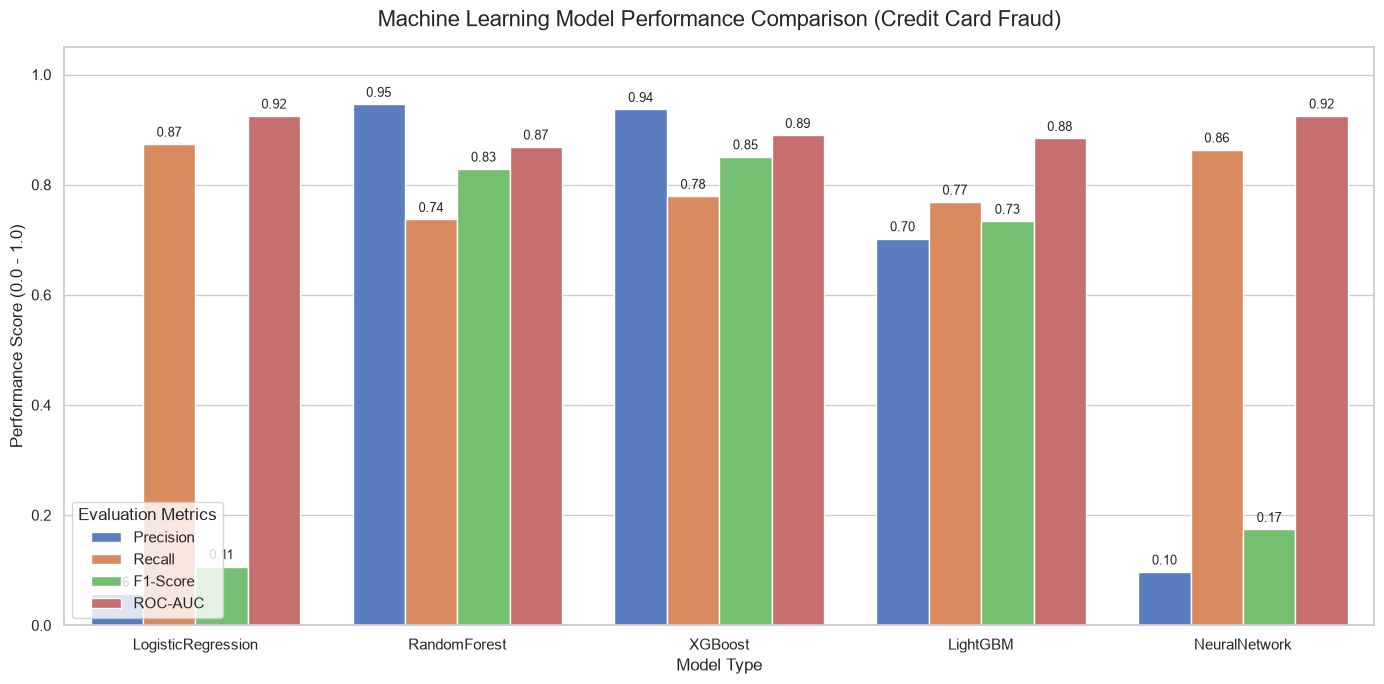

In [51]:
df_melted = df_metrics.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(14, 7))
sns.set_theme(style='whitegrid')

ax = sns.barplot(data=df_melted, x='Model', y='Score', hue='Metric', palette='muted')

plt.title('Machine Learning Model Performance Comparison (Credit Card Fraud)', fontsize=16, pad=15)
plt.xlabel('Model Type', fontsize=12)
plt.ylabel('Performance Score (0.0 - 1.0)', fontsize=12)
plt.ylim(0, 1.05)


for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f'{p.get_height():.2f}', 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', 
                    xytext=(0, 8), 
                    textcoords='offset points', 
                    fontsize=9)

plt.legend(title='Evaluation Metrics', loc='lower left')
plt.tight_layout()
plt.show()

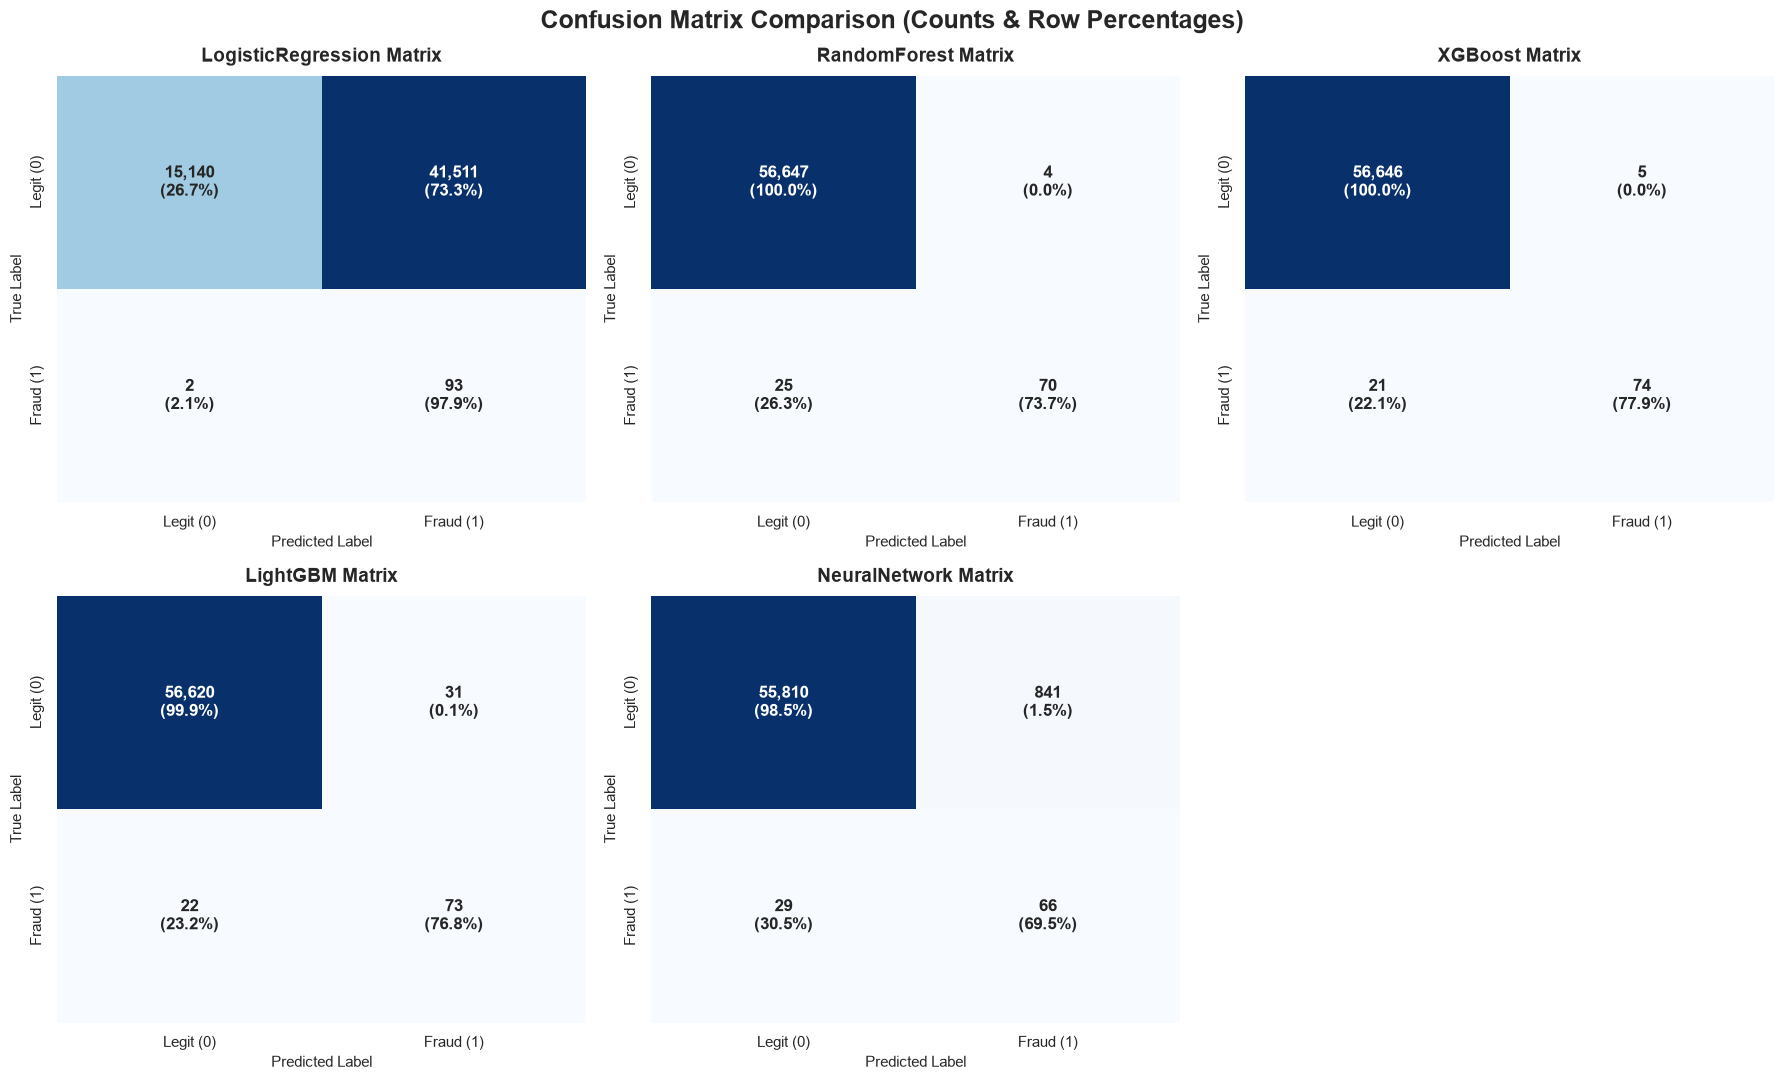

In [52]:
from sklearn.metrics import confusion_matrix


fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for i, (model_name, best_model) in enumerate(best_models_dict.items()):
    ax = axes[i]
    
    y_pred = best_model.predict(X_test)
    
    cm = confusion_matrix(y_test, y_pred)
    
    cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
    
    labels = np.array([
        [f"{cm[0,0]:,}\n({cm_percent[0,0]:.1f}%)", f"{cm[0,1]:,}\n({cm_percent[0,1]:.1f}%)"],
        [f"{cm[1,0]:,}\n({cm_percent[1,0]:.1f}%)", f"{cm[1,1]:,}\n({cm_percent[1,1]:.1f}%)"]
    ])
    
    sns.heatmap(
        cm, 
        annot=labels, 
        fmt="", 
        cmap='Blues', 
        cbar=False, 
        ax=ax,
        xticklabels=['Legit (0)', 'Fraud (1)'],
        yticklabels=['Legit (0)', 'Fraud (1)'],
        annot_kws={"size": 12, "weight": "bold"}
    )
    
    ax.set_title(f'{model_name} Matrix', fontsize=14, pad=10, weight='bold')
    ax.set_xlabel('Predicted Label', fontsize=11)
    ax.set_ylabel('True Label', fontsize=11)

fig.delaxes(axes[5])

plt.suptitle('Confusion Matrix Comparison (Counts & Row Percentages)', fontsize=18, weight='bold', y=0.98)
plt.tight_layout()
plt.show()